In [11]:
import sys
!{sys.executable} -m pip install pandas numpy seaborn matplotlib scikit-learn tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

%matplotlib inline

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [13]:
df = pd.read_csv('Churn_Modelling - Churn_Modelling.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [14]:
# Basic information about the dataset
display(df.describe())
print("Missing values in each column:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Missing values in each column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Data types:
RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


In [15]:
# Remove columns that do not help predict customer churn
df = df.drop(['RowNumber', 'Surname', 'CustomerId'], axis=1)

# Remove rows with missing values, if any
df = df.dropna()

print("Shape after preprocessing:", df.shape)
df.head()

Shape after preprocessing: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [16]:
def visualization(churned, not_churned, xlabel):
    plt.figure(figsize=(10, 5))
    plt.hist([churned, not_churned],
             color=['red', 'green'],
             label=['Exited', 'Not Exited'],
             bins=20)
    plt.xlabel(xlabel, fontsize=13)
    plt.ylabel("Number of customers", fontsize=13)
    plt.title(f"Customer Churn by {xlabel}")
    plt.legend()
    plt.show()

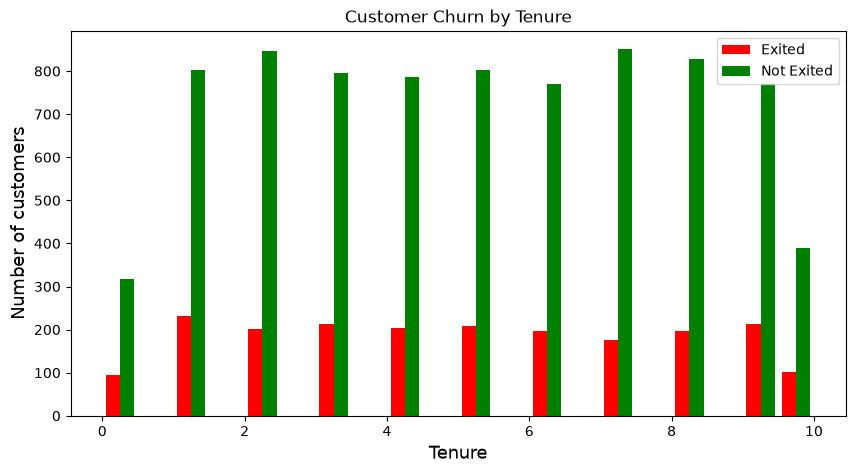

In [17]:
# Compare tenure for customers who exited and did not exit
df_churn_exited = df[df['Exited'] == 1]['Tenure']
df_churn_not_exited = df[df['Exited'] == 0]['Tenure']

visualization(df_churn_exited, df_churn_not_exited, "Tenure")

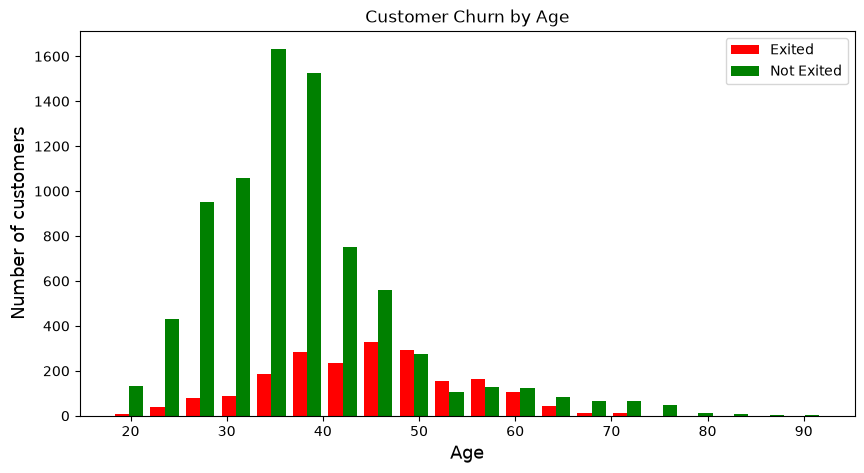

In [18]:
# Compare age for customers who exited and did not exit
df_churn_exited_age = df[df['Exited'] == 1]['Age']
df_churn_not_exited_age = df[df['Exited'] == 0]['Age']

visualization(df_churn_exited_age, df_churn_not_exited_age, "Age")

In [19]:
# One-hot encode Geography and Gender
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [20]:
# Input features and target variable
X = df.drop('Exited', axis=1)
y = df['Exited']

# Split data: 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Number of input features:", X_train.shape[1])

X_train: (7000, 11)
X_test: (3000, 11)
y_train: (7000,)
y_test: (3000,)
Number of input features: 11


In [21]:
# Standardize features: mean = 0 and standard deviation = 1
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [22]:
# Create a Sequential neural network
classifier = Sequential()

# First hidden layer
classifier.add(Dense(
    units=6,
    activation='relu',
    kernel_initializer='uniform',
    input_dim=X_train.shape[1]
))

# Second hidden layer
classifier.add(Dense(
    units=6,
    activation='relu',
    kernel_initializer='uniform'
))

# Output layer: one neuron for binary classification
classifier.add(Dense(
    units=1,
    activation='sigmoid',
    kernel_initializer='uniform'
))

In [23]:
# Compile the neural network
classifier.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
classifier.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = classifier.fit(
    X_train,
    y_train,
    batch_size=10,
    epochs=50,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7973 - loss: 0.5052 - val_accuracy: 0.7871 - val_loss: 0.4358
Epoch 2/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7973 - loss: 0.4348 - val_accuracy: 0.7871 - val_loss: 0.4287
Epoch 3/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7973 - loss: 0.4297 - val_accuracy: 0.7871 - val_loss: 0.4243
Epoch 4/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7971 - loss: 0.4258 - val_accuracy: 0.8186 - val_loss: 0.4200
Epoch 5/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8243 - loss: 0.4218 - val_accuracy: 0.8314 - val_loss: 0.4161
Epoch 6/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8286 - loss: 0.4179 - val_accuracy: 0.8214 - val_loss: 0.4131
Epoch 7/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8308 - loss: 0.4147 - val_accuracy: 0.8243 - val_loss: 0.4104
Epoch 8/50
630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8330 - loss: 0.4121 - val_accuracy: 0.

In [29]:
# Predict probabilities and convert them into class labels
y_pred_probability = classifier.predict(X_test)
y_pred = (y_pred_probability > 0.5).astype(int).ravel()

print("First 20 predictions:")
print(y_pred[:20])

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1]


In [30]:
# Confusion matrix and accuracy
cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print("Confusion Matrix:")
print(cm)
print("\nAccuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[2321   68]
 [ 409  202]]

Accuracy: 0.841

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91      2389
           1       0.75      0.33      0.46       611

    accuracy                           0.84      3000
   macro avg       0.80      0.65      0.68      3000
weighted avg       0.83      0.84      0.82      3000



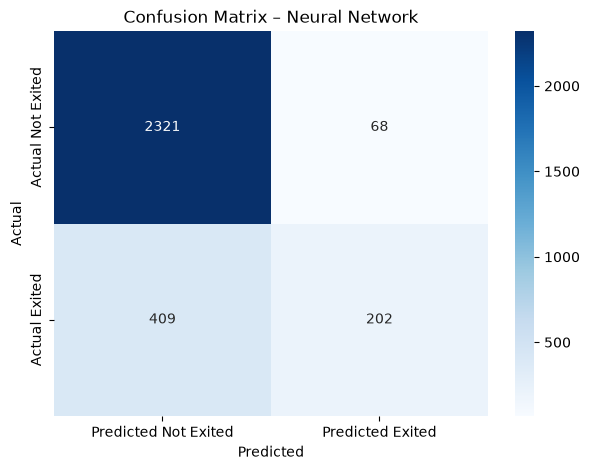

In [31]:
# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted Not Exited', 'Predicted Exited'],
    yticklabels=['Actual Not Exited', 'Actual Exited']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix – Neural Network')
plt.show()

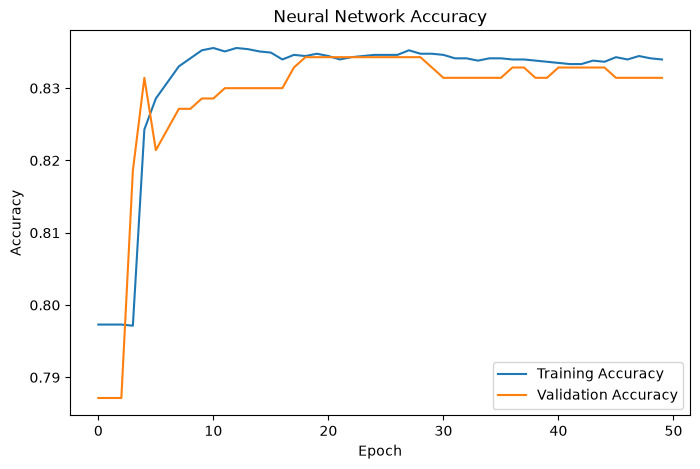

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Neural Network Accuracy')
plt.legend()
plt.show()